Import the modules that will be used.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

a) O(n) as theres same number of multiplications as there are elements in a vector.

b) O(n^2) each row of a matrix u do dot product function with the vector and as there is n rows you do O(n) x n = O(n^2)

c) O(n^3) as total number of n^2 steps as each row gets x by each column and each x is O(n) so n^2 x n = n^3

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [19]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

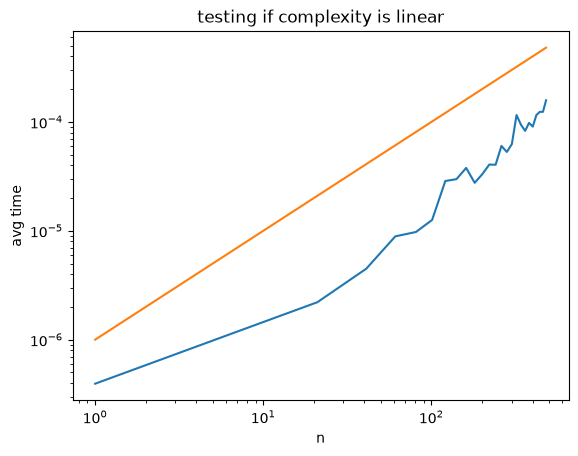

In [20]:
# if complexity is o(n) then when we plot a graph of time against n it should be linear
import time # in order to use time.perf_counter to measure time
import matplotlib.pyplot as plt
import numpy as np


no_values = np.arange(1, 500, 20)
times = []

for n in no_values:
    #starts timer
    start_time = time.perf_counter() # %timeit -q -0 factorial(int(n)) did not work so replaced with this

    for i in range(100): # repeat 100 times and then get an average 
        factorial(int(n))

    end_time = time.perf_counter()

    times.append((end_time - start_time)/100) # puts the times into the time list

plt.plot(no_values, times)
plt.loglog(no_values, 1e-6*no_values,) #compare to reference line

plt.xlabel('n')
plt.ylabel('avg time')
plt.title('testing if complexity is linear')
plt.show()


    

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [13]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [14]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [17]:
import time # in order to use time.perf_counter to measure time
import matplotlib.pyplot as plt
import numpy as np

# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 12)
times = []
for n in N:
    A = np.random.rand(n, n)
    start_time = time.perf_counter()
    det = np.linalg.slogdet(A)
    end_time = time.perf_counter()
    times.append(end_time - start_time)

Plot result:

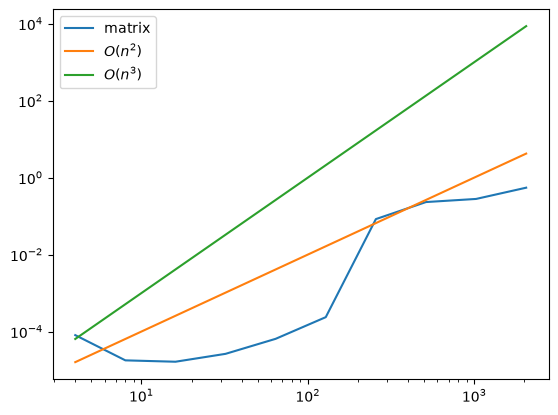

In [18]:
plt.loglog(N, times, label='matrix')
plt.loglog(N, 1e-6*N**2, label='$O(n^2)$')
plt.loglog(N, 1e-6*N**3, label='$O(n^3)$')
plt.legend(loc=0)
plt.show()
